# Kesit İstatistik — Matematiksel temel

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Permütasyon ve kombinasyon

Bir partiden kontrol örneği kaç farklı biçimde seçilebilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Sıralı seçimin neden daha çok sonuç ürettiğini karşılaştır.

**Yorum sınırı:** Bu sayma modeli yerine koymadan ve eşit olasılıklı seçim içindir.

**Alıştırma:** n=12, k=3 yerine k=5 kullan; kombinasyonun neden monoton artmadığını açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'sirasiz': 220, 'sirali': 1320, 'oran': 6.0}


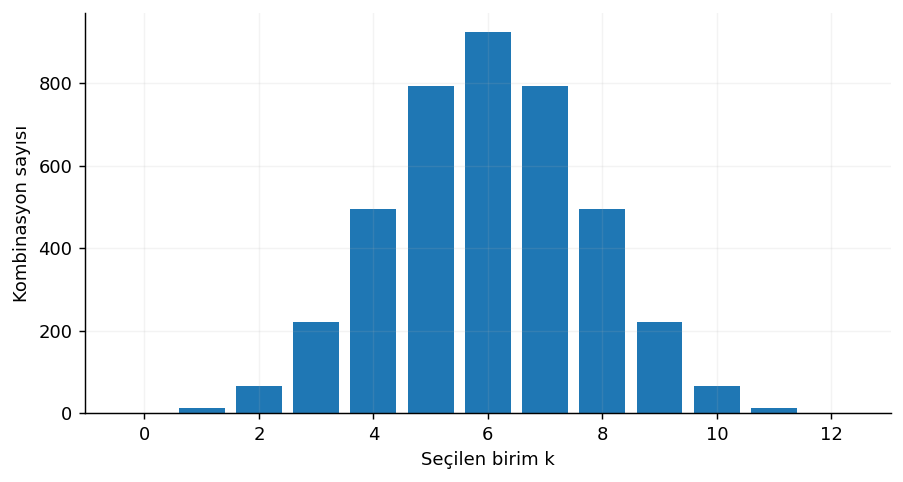

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from math import comb, perm
n,k=12,3
print({'sirasiz':comb(n,k),'sirali':perm(n,k),'oran':perm(n,k)/comb(n,k)})
ks=np.arange(n+1);plt.bar(ks,[comb(n,int(j)) for j in ks]);plt.xlabel('Seçilen birim k');plt.ylabel('Kombinasyon sayısı')
assert perm(n,k)==comb(n,k)*perm(k,k)

## Ortak, marjinal ve koşullu dağılımlar

Hacim bilgisi süre tahminini nasıl günceller?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Noktaların eğimini ve X=1 için koşullu ortalamayı birlikte oku.

**Yorum sınırı:** İki değişkenli normal modelin koşullu formülü kullanılır; her veri için geçerli değildir.

**Alıştırma:** Korelasyonu .7’den -.4’e değiştir; marjinal ve koşullu ortalamaları ayır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'marjinal_EY': 0, 'kosullu_EY_X1': 0.7, 'kosullu_varyans': 0.51}


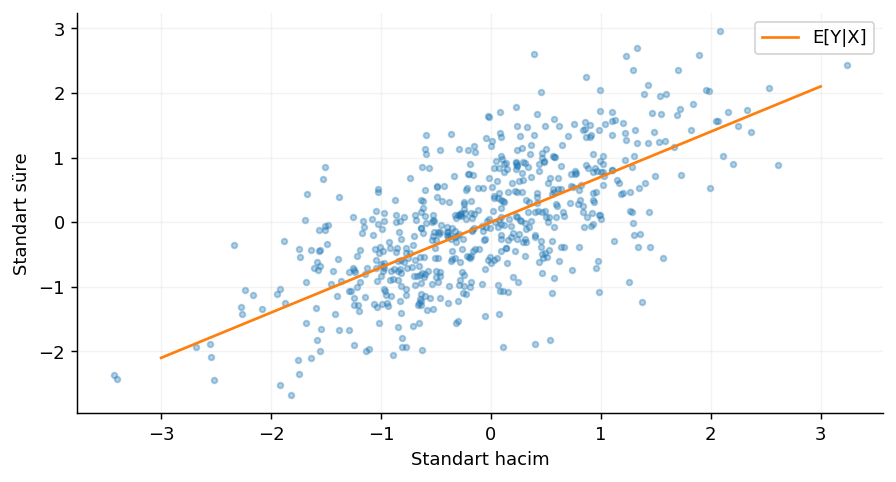

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

rho=.7;xy=rng.multivariate_normal([0,0],[[1,rho],[rho,1]],600)
x0=1.;print({'marjinal_EY':0,'kosullu_EY_X1':rho*x0,'kosullu_varyans':1-rho**2})
plt.scatter(*xy.T,s=10,alpha=.35);plt.plot([-3,3],rho*np.array([-3,3]),c='tab:orange',label='E[Y|X]');plt.xlabel('Standart hacim');plt.ylabel('Standart süre');plt.legend()

## Değişken dönüşümleri ve delta yöntemi

Log dönüşümü ortalama belirsizliğini nasıl değiştirir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Bootstrap log-ortalama dağılımını delta aralığıyla karşılaştır.

**Yorum sınırı:** Delta yaklaşımı düzgün dönüşüm ve yeterli örneklem ister; log ortalama ile ortalama log farklıdır.

**Alıştırma:** n=80 yerine n=15 kullan ve yaklaşım farkını yorumla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'log_ortalama': np.float64(2.180661303807213), 'delta_SE': np.float64(0.05412841990426161), 'bootstrap_SE': np.float64(0.053410959811427974)}


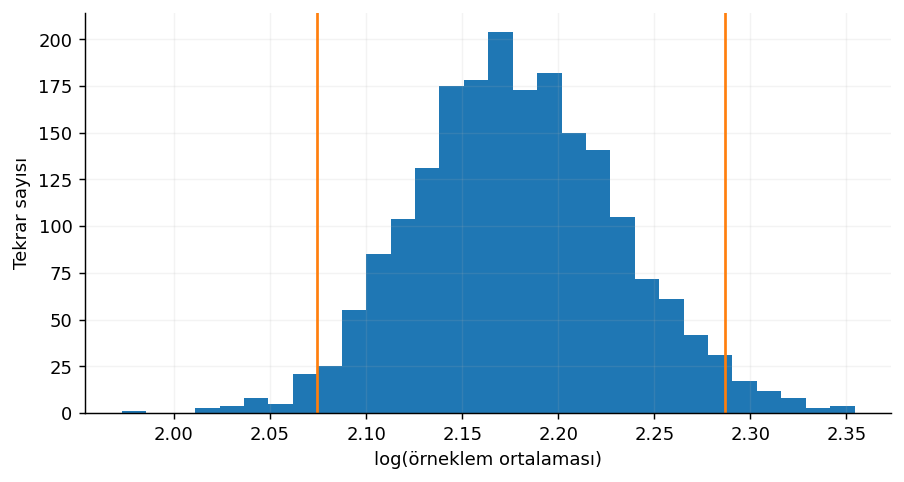

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.lognormal(2,.5,80);mu=x.mean();se=x.std(ddof=1)/np.sqrt(len(x));delta=se/mu
boot=np.log(rng.choice(x,(2000,len(x))).mean(axis=1));print({'log_ortalama':np.log(mu),'delta_SE':delta,'bootstrap_SE':boot.std(ddof=1)})
plt.hist(boot,bins=30);plt.axvline(np.log(mu)-1.96*delta,c='tab:orange');plt.axvline(np.log(mu)+1.96*delta,c='tab:orange');plt.xlabel('log(örneklem ortalaması)');plt.ylabel('Tekrar sayısı')

## Büyük sayılar yasası ve olasılık sınırları

Daha çok veri hangi oynaklığı azaltır?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** n arttığında sapma olasılığı ile Chebyshev üst sınırını karşılaştır.

**Yorum sınırı:** Sınır gevşek olabilir; bağımsız sonlu varyanslı üstel veri kullanılır.

**Alıştırma:** Sapma eşiğini .3 yerine .15 yap; gerekli n üzerindeki etkiyi açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


     n  gozlenen  Chebyshev
0    5  0.493000   1.000000
1   10  0.315333   1.000000
2   20  0.183000   0.555556
3   50  0.036000   0.222222
4  100  0.003667   0.111111
5  200  0.000000   0.055556


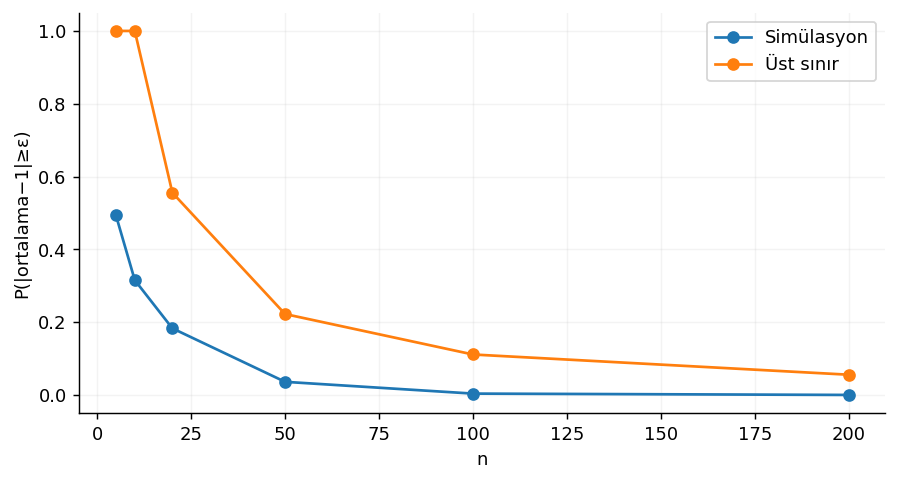

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

ns=np.array([5,10,20,50,100,200]);eps=.3
observed=[np.mean(np.abs(rng.exponential(1,(3000,int(n))).mean(axis=1)-1)>=eps) for n in ns]
bound=np.minimum(1,1/(ns*eps**2));print(pd.DataFrame({'n':ns,'gozlenen':observed,'Chebyshev':bound}))
plt.plot(ns,observed,'o-',label='Simülasyon');plt.plot(ns,bound,'o-',label='Üst sınır');plt.xlabel('n');plt.ylabel('P(|ortalama−1|≥ε)');plt.legend()